In [6]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/marianursarescu/new-ic3-dataset-era5/modis_ndvi_2015_2025.csv
/kaggle/input/datasets/marianursarescu/new-ic3-dataset-era5/reanalysis-era5-land-timeseries-sfc-2m-temperaturexgdjivww.nc
/kaggle/input/datasets/marianursarescu/new-ic3-dataset-era5/reanalysis-era5-land-timeseries-sfc-pressure-precipitationt19uaucl.nc
/kaggle/input/datasets/marianursarescu/new-ic3-dataset-era5/reanalysis-era5-land-timeseries-sfc-soil-waterx3qt0cyw.nc


In [7]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob

files = glob.glob("/kaggle/input/**/*.nc", recursive=True)
csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print("Fisiere NetCDF:", len(files))
print("Fisiere CSV:", len(csv_files))

ds_temp = xr.open_dataset(
    next(f for f in files if "temperature" in f)
)

ds_prec = xr.open_dataset(
    next(f for f in files if "precipitation" in f)
)

ds_sol = xr.open_dataset(
    next(f for f in files if "soil-water" in f)
)

ds = xr.merge([ds_temp, ds_prec, ds_sol])

df_ndvi = pd.read_csv(
    next(f for f in csv_files if "modis_ndvi" in f)
)

print(ds)
print(df_ndvi.head())

Fisiere NetCDF: 3
Fisiere CSV: 1
<xarray.Dataset> Size: 29MB
Dimensions:     (valid_time: 96432, latitude: 3, longitude: 6)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 771kB 2015-01-01 ... 2025-12-31T2...
  * latitude    (latitude) float64 24B 44.5 44.6 44.7
  * longitude   (longitude) float64 48B 23.8 23.9 24.0 24.1 24.2 24.3
Data variables:
    t2m         (valid_time, latitude, longitude) float32 7MB ...
    tp          (valid_time, latitude, longitude) float32 7MB ...
    swvl1       (valid_time, latitude, longitude) float32 7MB ...
    swvl2       (valid_time, latitude, longitude) float32 7MB ...
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2025-02-10T00:00 GRIB to CDM+CF via cfgrib-0.9.1...
    institution:             European Centre for Medium-Range Weather For

In [8]:
print("Variabile disponibile:")

for var in ds.data_vars:
    print(var, ds[var].attrs.get("units", "Unitate necunoscuta"))

print("\nCoordonate:")
print(ds.coords)

print("\nDimensiuni:")
print(ds.sizes)

print("\nMODIS NDVI:")
print(df_ndvi.shape)

Variabile disponibile:
t2m K
tp m
swvl1 m**3 m**-3
swvl2 m**3 m**-3

Coordonate:
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 771kB 2015-01-01 ... 2025-12-31T2...
  * latitude    (latitude) float64 24B 44.5 44.6 44.7
  * longitude   (longitude) float64 48B 23.8 23.9 24.0 24.1 24.2 24.3

Dimensiuni:
Frozen({'valid_time': 96432, 'latitude': 3, 'longitude': 6})

MODIS NDVI:
(253, 2)


In [9]:
print("Valori lipsa ERA5-Land:")

for var in ds.data_vars:
    missing = ds[var].isnull().sum().item()
    total = ds[var].size

    print(f"{var}: {missing}/{total} ({100 * missing / total:.2f}%)")

print("\nValori lipsa MODIS:")
print(df_ndvi.isnull().sum())

Valori lipsa ERA5-Land:
t2m: 0/1735776 (0.00%)
tp: 0/1735776 (0.00%)
swvl1: 0/1735776 (0.00%)
swvl2: 0/1735776 (0.00%)

Valori lipsa MODIS:
NDVI    0
data    0
dtype: int64


In [10]:
# Selectam variabilele
data = ds[["t2m", "tp", "swvl1", "swvl2"]].copy()

# Temperatura in grade Celsius
data["temperature_c"] = data["t2m"] - 273.15

# Umiditatea medie a solului (0-28 cm)
data["soil_moisture"] = (
    data["swvl1"] * 7 +
    data["swvl2"] * 21
) / 28

# Media spatiala a regiunii
regional = data[
    ["temperature_c", "tp", "soil_moisture"]
].mean(dim=["latitude", "longitude"])

# Agregarea temperaturii si umiditatii la nivel zilnic
temp_daily = regional["temperature_c"].resample(
    valid_time="1D"
).mean()

soil_daily = regional["soil_moisture"].resample(
    valid_time="1D"
).mean()

# Precipitatii: transformam acumularile in valori orare
tp = regional["tp"]

tp_previous = tp.shift(valid_time=1)

hour = tp.valid_time.dt.hour

tp_hourly = xr.where(
    hour == 1,
    tp,
    tp - tp_previous
)

# La ora 00:00 folosim diferenta fata de ora 23:00
# din ciclul precedent; nu diferenta dintre doua zile
tp_hourly = xr.where(hour == 0, tp - tp_previous, tp_hourly)

# Corectam resetarea acumularii dupa ora 00:00
tp_hourly = xr.where(hour == 1, tp, tp_hourly)

# Eliminam diferentele negative provocate de resetari
tp_hourly = tp_hourly.clip(min=0)

# Precipitatiile pentru ziua D sunt acumulate pana la
# ora 00:00 a zilei D+1
prec_daily = tp_hourly.resample(
    valid_time="1D", closed="right", label="left"
).sum() * 1000

# Construim DataFrame-ul
df = pd.DataFrame({
    "date": pd.to_datetime(temp_daily.valid_time.values),
    "temperature_c": temp_daily.values,
    "soil_moisture": soil_daily.values
})

df_prec = pd.DataFrame({
    "date": pd.to_datetime(prec_daily.valid_time.values),
    "precipitation_mm": prec_daily.values
})

df = df.merge(df_prec, on="date", how="left")

print(df.head())
print("\nDimensiuni:", df.shape)

        date  temperature_c  soil_moisture  precipitation_mm
0 2015-01-01     -13.684741       0.371719          0.003309
1 2015-01-02      -5.223634       0.370098          0.002842
2 2015-01-03       0.437639       0.371607          0.002564
3 2015-01-04       0.069644       0.374845          0.829599
4 2015-01-05      -2.093232       0.375143          0.002209

Dimensiuni: (4018, 4)


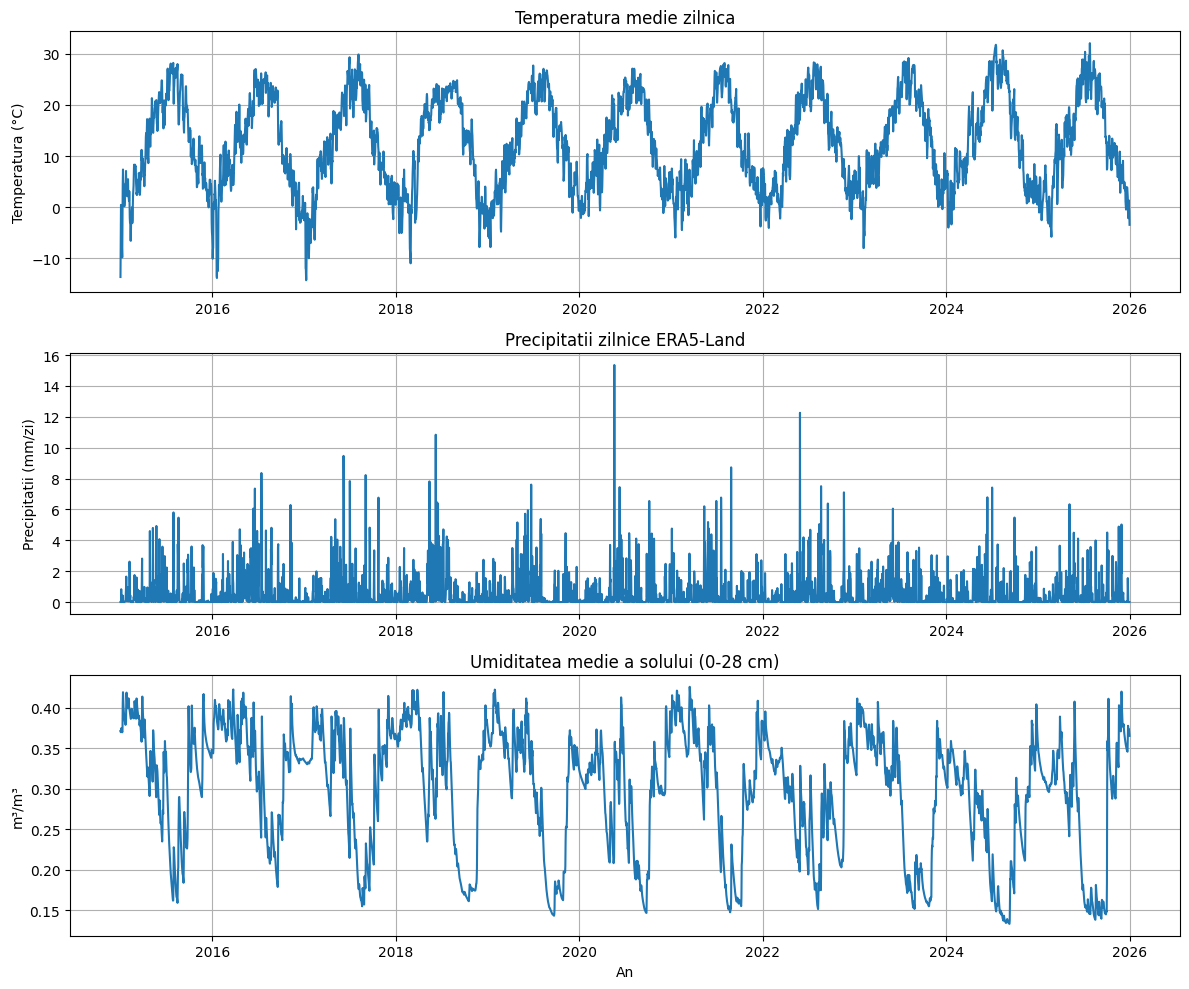

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(df["date"], df["temperature_c"])
axes[0].set_title("Temperatura medie zilnica")
axes[0].set_ylabel("Temperatura (°C)")
axes[0].grid(True)

axes[1].plot(df["date"], df["precipitation_mm"])
axes[1].set_title("Precipitatii zilnice ERA5-Land")
axes[1].set_ylabel("Precipitatii (mm/zi)")
axes[1].grid(True)

axes[2].plot(df["date"], df["soil_moisture"])
axes[2].set_title("Umiditatea medie a solului (0-28 cm)")
axes[2].set_ylabel("m³/m³")
axes[2].set_xlabel("An")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [12]:
# Pregatim datele MODIS
df_ndvi["data"] = pd.to_datetime(df_ndvi["data"])

df_ndvi = df_ndvi.sort_values("data")
df = df.sort_values("date")

# Asociem fiecarei zile ultima observatie NDVI
df = pd.merge_asof(
    df,
    df_ndvi[["data", "NDVI"]],
    left_on="date",
    right_on="data",
    direction="backward",
    tolerance=pd.Timedelta(days=16)
)

df = df.drop(columns=["data"])

print(df.head())
print("\nDimensiuni:", df.shape)
print("\nValori lipsa:")
print(df.isnull().sum())

        date  temperature_c  soil_moisture  precipitation_mm      NDVI
0 2015-01-01     -13.684741       0.371719          0.003309  0.224061
1 2015-01-02      -5.223634       0.370098          0.002842  0.224061
2 2015-01-03       0.437639       0.371607          0.002564  0.224061
3 2015-01-04       0.069644       0.374845          0.829599  0.224061
4 2015-01-05      -2.093232       0.375143          0.002209  0.224061

Dimensiuni: (4018, 5)

Valori lipsa:
date                0
temperature_c       0
soil_moisture       0
precipitation_mm    0
NDVI                0
dtype: int64


In [18]:
# Eliminam coloanele daca exista deja
df = df.drop(columns=["mean", "std", "SSMI"], errors="ignore")

# Extragem luna calendaristica
df["month"] = df["date"].dt.month

# Perioada de referinta: doar train
train_reference = df[df["date"] < "2022-01-01"]

# Calculam media si abaterea standard pentru fiecare luna
monthly_stats = train_reference.groupby("month")[
    "soil_moisture"
].agg(
    mean="mean",
    std="std"
)

# Adaugam statisticile in tabel
df = df.join(monthly_stats, on="month")

# Calculam indicele SSMI
df["SSMI"] = (
    df["soil_moisture"] - df["mean"]
) / df["std"]

# Afisam rezultatele
print(df[["date", "soil_moisture", "SSMI"]].head())

print("\nValori lipsa SSMI:")
print(df["SSMI"].isnull().sum())

        date  soil_moisture      SSMI
0 2015-01-01       0.371719  0.177978
1 2015-01-02       0.370098  0.128832
2 2015-01-03       0.371607  0.174599
3 2015-01-04       0.374845  0.272751
4 2015-01-05       0.375143  0.281778

Valori lipsa SSMI:
0


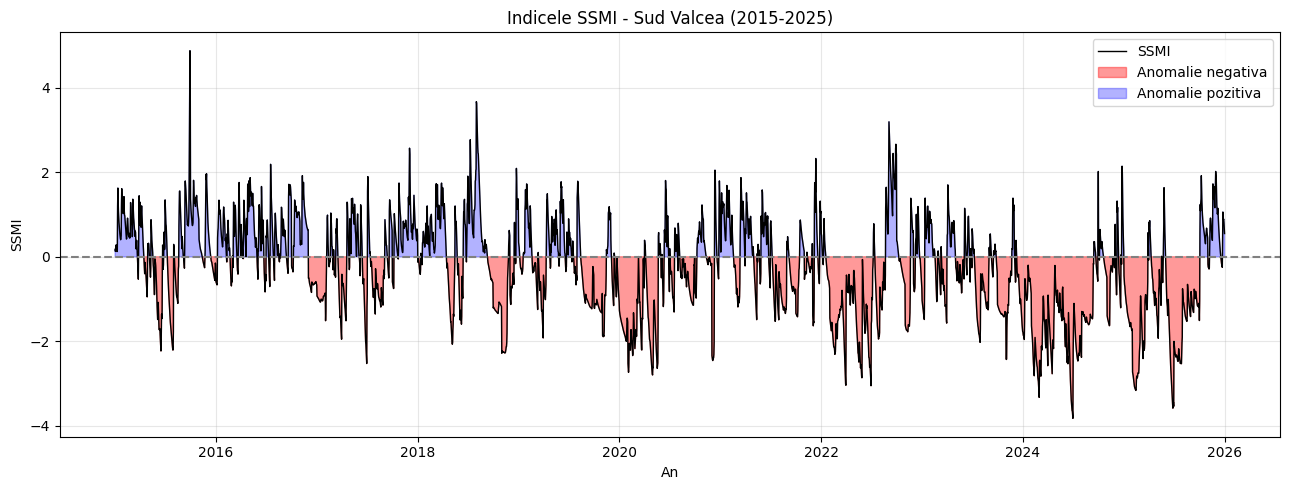

In [19]:
plt.figure(figsize=(13, 5))

plt.plot(
    df["date"],
    df["SSMI"],
    color="black",
    linewidth=1,
    label="SSMI"
)

plt.axhline(0, color="gray", linestyle="--")

plt.fill_between(
    df["date"], df["SSMI"], 0,
    where=df["SSMI"] < 0,
    color="red", alpha=0.4,
    label="Anomalie negativa"
)

plt.fill_between(
    df["date"], df["SSMI"], 0,
    where=df["SSMI"] >= 0,
    color="blue", alpha=0.3,
    label="Anomalie pozitiva"
)

plt.title("Indicele SSMI - Sud Valcea (2015-2025)")
plt.xlabel("An")
plt.ylabel("SSMI")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
train = df[df["date"] < "2022-01-01"].copy()

val = df[
    (df["date"] >= "2022-01-01") &
    (df["date"] < "2024-01-01")
].copy()

test = df[df["date"] >= "2024-01-01"].copy()

print("Train:", len(train), "zile")
print("Validation:", len(val), "zile")
print("Test:", len(test), "zile")

# Salvam datele preprocesate
df.to_csv(
    "/kaggle/working/era5_modis_valcea_processed.csv",
    index=False
)

Train: 2557 zile
Validation: 730 zile
Test: 731 zile


In [21]:
print("Latitudini:", ds.latitude.values)
print("Longitudini:", ds.longitude.values)

print("\nPerioada:")
print("Start:", str(ds.valid_time.values[0]))
print("Final:", str(ds.valid_time.values[-1]))

print("\nRezolutie spatiala:")
print("Latitudine:",
      abs(float(ds.latitude.diff("latitude").mean())))
print("Longitudine:",
      abs(float(ds.longitude.diff("longitude").mean())))

print("\nNumar puncte geografice:",
      ds.sizes["latitude"] * ds.sizes["longitude"])

print("\nDimensiune finala:", df.shape)
print("\nValori lipsa:")
print(df.isnull().sum())

Latitudini: [44.5 44.6 44.7]
Longitudini: [23.8 23.9 24.  24.1 24.2 24.3]

Perioada:
Start: 2015-01-01T00:00:00.000000000
Final: 2025-12-31T23:00:00.000000000

Rezolutie spatiala:
Latitudine: 0.10000000000000142
Longitudine: 0.1

Numar puncte geografice: 18

Dimensiune finala: (4018, 9)

Valori lipsa:
date                0
temperature_c       0
soil_moisture       0
precipitation_mm    0
NDVI                0
month               0
mean                0
std                 0
SSMI                0
dtype: int64
